<a href="https://colab.research.google.com/github/maramgueye/datascience_with_python/blob/machine_learning/L3_03_homework_titanic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Homework — Who survived the Titanic?
**Lecture 3 · Logistic Regression · after the lecture**

This notebook walks through a classification project from A to Z, in the 12 steps of the lecture (slides 25–28):
1 Frame the question · 2 Load the data · 3 Inspect · 4 Split · 5 Baseline · 6 Prepare the features · 7 Fit · 8 Interpret · 9 Evaluate on validation · 10 Decide · 11 Test once · 12 Report.

Complete every cell marked `TODO`, one step per line, as in class. Write your answers in the markdown cells. The questions are on the investigation sheet `L3_03_homework_titanic_questions.pdf`.

## 1. Frame the question
**Main question:** which passengers survived the Titanic, and what does that say about the society on board?

- One row is one passenger. The target is `Survived`: 1 = survived (the **positive class**), 0 = died.
- The inputs we study, one at a time: `Age`, `Fare` and `Sex`. `Pclass` (ticket class) comes back in the report.
- The goal is to **understand** who survived, not to forecast anything: the ship sank in 1912. The models are tools to read the data, and their scores tell us how much each input says about survival.

### Q1 — Frame the question

**Your answer:**
1. One row of the data is one passenger of the titanic and informations about him/her like survivor?, age, class, sex, fare
The target is survivor and the positive class is 1 (survived)
2. It is a classification problem because we have a yes or no questions "did this passenger survivor?" we can even add that it is a binary classification and we are not looking for a numerical value
3. We are trying to understand who survived. Compare to if we were trying to predict new passengers, when trying to understand something from previous data we have the outcome, we already know who survived or not. We mostly want to understant how or "why" they survived


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving titanic_passengers.csv to titanic_passengers.csv


## 2. Load the data

In [91]:
import numpy as np                                     # numbers and arrays
import pandas as pd                                    # tables of data
import matplotlib.pyplot as plt                        # plots
from sklearn.model_selection import train_test_split   # to split the rows
from sklearn.dummy import DummyClassifier              # the baseline
from sklearn.linear_model import LogisticRegression    # the model
from sklearn.metrics import confusion_matrix           # the four counts
from sklearn.metrics import accuracy_score             # share of correct decisions
from sklearn.metrics import balanced_accuracy_score    # mean of the two recalls

passengers = pd.read_csv("titanic_passengers.csv")       # one row per passenger
print(passengers.shape)                                       # (rows, columns)
columns_used = ["Survived", "Pclass", "Sex", "Age", "Fare"]   # the five columns we use
display(passengers[columns_used].head())                      # the first five rows

(891, 12)


,Survived,Pclass,Sex,Age,Fare
0,0,3,male,22.0,7.2500
1,1,1,female,38.0,71.2833
2,1,3,female,26.0,7.9250
3,1,1,female,35.0,53.1000
4,0,3,male,35.0,8.0500


In [93]:
passengers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
passengers.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
(passengers['Survived']==1).sum()

np.int64(342)

In [ ]:
passengers['Fare'].median()

14.4542

In [ ]:
def binned_share(data, column, edges):
    """Share of survivors and number of passengers in each band of `column`."""
    bands = pd.cut(data[column], edges)                       # band of each row
    groups = data.groupby(bands, observed=True)["Survived"]   # one group per band
    table = groups.agg(["mean", "size"])                      # share and count
    table.columns = ["share survived", "passengers"]          # readable names
    middles = [(band.left + band.right) / 2 for band in table.index]  # band centres
    table["band middle"] = middles                            # x position of the dot
    return table.round(3)


def plot_shares(table, xlabel):
    """Dots: share survived per band; dot size: number of passengers."""
    fig, ax = plt.subplots(figsize=(8, 4))                # an empty figure
    ax.scatter(table["band middle"], table["share survived"],
               s=table["passengers"] * 2,                 # dot size: passengers
               color="#FF6666", edgecolor="white")        # one dot per band
    ax.set_ylim(-0.03, 1.03)                              # shares go from 0 to 1
    ax.set_xlabel(xlabel)                                 # name of the input
    ax.set_ylabel("share survived")                       # name of the y axis
    return ax

## 3. Inspect
Check the whole file before anything else: its size, the column types, the missing values and how many passengers survived. We do **not** look at how survival depends on age or fare yet: those patterns are studied on the training rows only, after the split (step 6).

### Q2 — Load and inspect

In [ ]:
passengers.info()          # column types and number of values present

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
# TODO: survivors, share survived, missing values per column, fare summary
n_survivors = passengers['PassengerId'].count()
share_survived = (passengers['Survived']==1).sum()
missing_per_column = None
fare_summary = passengers['Fare'].describe()

print('numbers of passengers:',n_survivors,"and numbers of survivors:", share_survived)
print(missing_per_column)
print(fare_summary)

numbers of passengers: 891 and numbers of survivors: 342
None
count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64


### **Answers**
1. We have 891 Passengers and 12 columns
2. 342 passengers survived
3. The columns Age, Cabin and embarked have missing values (respectively 177, 687,and 2)
4. The median fare is 14,4542 and the mean is 32.204208 we can notice that the distribution is right skew. We know that in the Titanic the fare were divided by class so we understand that the possible minority of highest paying passengers make the mean go up when a majority of the passenger pay the lowest far.

## 4. Split
Split the passengers **before** looking at any pattern, in three parts:
- **train** (60%): to look at the data and fit the models;
- **validation** (20%): to compare the models and choose one;
- **test** (20%): to score the chosen model **once**, at the end.

`stratify` keeps the share of survivors the same in the three parts. `random_state` fixes the random shuffle, so everyone gets the same rows every time the notebook runs.

### Q3 — Split

In [109]:
# First cut: 20% of the passengers become the test rows
rest, test = train_test_split(passengers, test_size=0.2,
                              stratify=passengers["Survived"], random_state=42)

# TODO: second cut: 25% of the rest become validation rows, the others training rows
train, validation = train_test_split(rest, test_size=0.25,
                              stratify=rest["Survived"], random_state=42)

print(len(train), len(validation), len(test))

534 178 179


In [110]:
# TODO: the share of survivors in each part
share_train = round(534/n_survivors,2)
share_validation = round(174/n_survivors,2)
share_test = round(179/n_survivors,2)
print(share_train, share_validation, share_test)

0.6 0.2 0.2


In [ ]:
train_test_split??

###**Your answer:**
2. stratify keeps the share of survivors the same in the three parts
3. random_state fixes the random shuffle, so everyone gets the same rows every time the notebook runs.
4. The Training set to train the models
The validation set to choose the best model
The test set to compute the erreor rate

## 5. Baseline
The baseline ignores the passenger and predicts the most frequent class of the training rows for everyone. Any model must beat it. We score it on the validation rows with two numbers:
- **accuracy**: the share of correct decisions;
- **balanced accuracy**: the mean of the share of victims found and the share of survivors found. It is 0.5 for any rule that ignores the passenger.

### Q4 — Baseline

In [ ]:
# 1. Choose the data
X_train_baseline = train[["Pclass"]]      # ignored by the baseline: any column
y_train = train["Survived"]               # target on the training rows
X_val_baseline = validation[["Pclass"]]   # same column on the validation rows
y_val = validation["Survived"]            # target on the validation rows

# 2. Create the baseline
baseline = DummyClassifier(strategy="most_frequent")                      # TODO: DummyClassifier, most frequent class

# 3. Fit on the training rows
baseline.fit(X_train_baseline, y_train)


# 4. Predict and score on the validation rows
predicted_baseline = baseline.predict(X_val_baseline)                 # TODO
accuracy_baseline = accuracy_score(y_val, predicted_baseline)                 # TODO
balanced_baseline = balanced_accuracy_score(y_val,predicted_baseline)          # TODO
print(accuracy_baseline, balanced_baseline)

0.6179775280898876 0.5


In [ ]:
balanced_accuracy_score??

**Your answer:**



## 6. Prepare the features
Look at each feature on the **training rows** only, then make it ready for the model: no missing values, numbers only. Whatever we compute here (for example a median) comes from the training rows and is then applied, unchanged, to the validation and test rows.

### Q5 — Age: look first, then fill the missing ages

,share survived,passengers,band middle
Age,,,
"(0, 5]",0.852,27,2.5
"(5, 10]",0.182,11,7.5
"(10, 15]",0.455,11,12.5
"(15, 20]",0.370,54,17.5
"(20, 30]",0.341,138,25.0
"(30, 40]",0.427,103,35.0
"(40, 50]",0.451,51,45.0
"(50, 60]",0.370,27,55.0
"(60, 80]",0.214,14,70.0


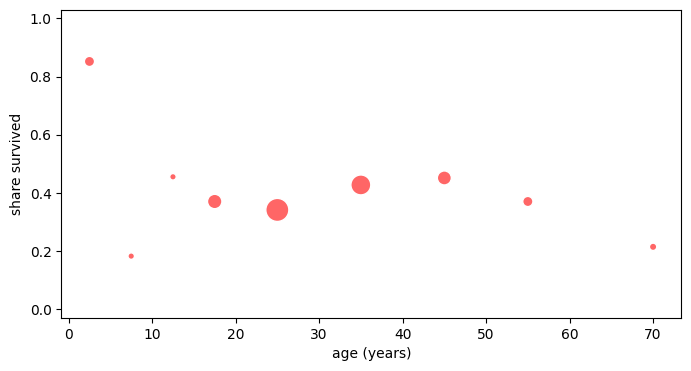

In [ ]:
age_edges = [0, 5, 10, 15, 20, 30, 40, 50, 60, 80]       # band limits in years
age_table = binned_share(train, "Age", age_edges)         # share per band, training rows
display(age_table)                                        # show the table
plot_shares(age_table, "age (years)")                     # one dot per band
plt.show()                                                # draw the figure

###**Answer**
We can see that the babies survived at a best rate with a85.2% survival rate abd that we see that the curve mostly fall stating really high with the babies, stabilizing a little bit between 37% and 45% survival for teen to middle age people (from 15yo to 50yo) then dropping hard when it with the older generation (60 to 80 yo)

In [108]:
# TODO: how many training passengers have no recorded age?
train[['Age']].info()

<class 'pandas.core.frame.DataFrame'>
Index: 534 entries, 577 to 219
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Age     436 non-null    float64
dtypes: float64(1)
memory usage: 8.3 KB


In [85]:
passengers['Age'].describe()

,Age
count,714.000000
mean,29.699118
std,14.526497
min,0.420000
25%,20.125000
50%,28.000000
75%,38.000000
max,80.000000


In [88]:
# TODO: fill missing ages with the training median age, in all three parts
median_age = train[['Age']].median()
# TODO: train
# TODO: validation
# TODO: test
print(median_age)

Age    29.0
dtype: float64


In [90]:
train.head(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
577,578,1,1,"Silvey, Mrs. William Baird (Alice Munger)",female,39.0,1,0,13507,55.9000,E44,S
63,64,0,3,"Skoog, Master. Harald",male,4.0,3,2,347088,27.9000,NaN,S
424,425,0,3,"Rosblom, Mr. Viktor Richard",male,18.0,1,1,370129,20.2125,NaN,S
513,514,1,1,"Rothschild, Mrs. Martin (Elizabeth L. Barrett)",female,54.0,1,0,PC 17603,59.4000,NaN,C
610,611,0,3,"Andersson, Mrs. Anders Johan (Alfrida Konstant...",female,39.0,1,5,347082,31.2750,NaN,S


###**Your answer:**
1. For the band that have fewer than 15 people, I will give them a weights of ...idk
2. They are 98 (534 - 436) passengers without a recorded age


In [147]:
train[['Age']]=train[['Age']].fillna(median_age)

### Q6 — Fare and sex

In [148]:
fare_edges = [-0.1, 8, 15, 30, 60, 600]                   # band limits in pounds
fare_table = binned_share(train, "Fare", fare_edges)      # share per band, training rows
display(fare_table)                                       # show the table

,share survived,passengers,band middle
Fare,,,
"(-0.1, 8.0]",0.210,143,3.95
"(8.0, 15.0]",0.284,134,11.50
"(15.0, 30.0]",0.439,123,22.50
"(30.0, 60.0]",0.516,64,45.00
"(60.0, 600.0]",0.714,70,330.00


###**answer**
The people that payed the highest fare are the one that have the highest survival rate. We notice a positive correlation between the amount payed in fare and the survival rate. We can also note that less people pay the more expensive fare.

In [149]:
print(train[['Fare']].median())

Fare    14.4542
dtype: float64


In [150]:
train.head(5)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,female,Female
577,578,1,1,"Silvey, Mrs. William Baird (Alice Munger)",female,39.0,1,0,13507,55.9000,E44,S,1,1
63,64,0,3,"Skoog, Master. Harald",male,4.0,3,2,347088,27.9000,NaN,S,0,0
424,425,0,3,"Rosblom, Mr. Viktor Richard",male,18.0,1,1,370129,20.2125,NaN,S,0,0
513,514,1,1,"Rothschild, Mrs. Martin (Elizabeth L. Barrett)",female,54.0,1,0,PC 17603,59.4000,NaN,C,1,1
610,611,0,3,"Andersson, Mrs. Anders Johan (Alfrida Konstant...",female,39.0,1,5,347082,31.2750,NaN,S,1,1


In [151]:
# TODO: the median fare in each class (1st, 2nd, 3rd), training rows
median_fare_by_class = train.groupby("Pclass")["Fare"].median()
print(median_fare_by_class)

Pclass
1    57.45420
2    13.67915
3     8.05000
Name: Fare, dtype: float64


In [152]:
# TODO: a column "female", 1 for women and 0 for men, in all three parts
train["Female"] = (train["Sex"] == "female").astype(int)
# TODO: train
# TODO: validation
validation["Female"]=(validation["Sex"]=="female").astype(int)
# TODO: test
test["Female"] = (test["Sex"] == "female").astype(int)
display(train[["Sex", "female"]].head())          # check the new column

,Sex,female
577,female,1
63,male,0
424,male,0
513,female,1
610,female,1


###**Your answer:**
We need it instead of Sex because models work on numbers, not words and the bianry (0 and 1) coding gives the model something meaningful to learn


## 7. Fit
Fit three one-feature logistic regressions on the **training rows**: age, fare, female. Each one is a pass through steps 6–8; step 9 compares them.

### Q7 — Fit three models

In [153]:
# 1. Choose the data (training rows)
# 2. Create the models
# 3. Fit
X_train_age = train[["Age"]]          # input: a table with one column
age_logit = LogisticRegression()
age_logit.fit(X_train_age, y_train)          # learn b and w for age


X_train_fare = train[["Fare"]]
fare_logit = LogisticRegression()
fare_logit.fit(X_train_fare, y_train)

X_train_female = train[["female"]]
female_logit = LogisticRegression()
female_logit.fit(X_train_female, y_train)

LogisticRegression()

**Your answer:**

# TODO

## 8. Interpret
Read b and w of each model, turn them into probabilities by hand, and check with `predict_proba`.

### Q8 — The age model

In [156]:
# 4. Read the fitted numbers
import numpy as np
#age
b_age = age_logit.intercept_[0]
w_age = age_logit.coef_[0][0]
odds_ratio_age_10 = np.exp(10*w_age)
print(b_age, w_age, odds_ratio_age_10)

-0.1116117018325715 -0.012183253180486674 0.8852966151152752


In [157]:
#fare
b_fare = fare_logit.intercept_[0]
w_fare = fare_logit.coef_[0][0]
odds_ratio_fare_10 = np.exp(10*w_fare)
print(b_fare, w_fare, odds_ratio_fare_10)

-1.043407487120996 0.019287657263732782 1.2127330998330235


In [158]:
#female
b_female = female_logit.intercept_[0]
w_female = female_logit.coef_[0][0]
odds_ratio_female_10 = np.exp(10*w_female)
print(b_female, w_female, odds_ratio_female_10)

-1.4154728878357827 2.400173679102551 26535168174.0358


In [ ]:
# By hand: p = 1 / (1 + exp(-(b + w * age)))
ages = np.array([5, 30, 70])                            # three ages at once
p_by_hand = None                                        # TODO
print(p_by_hand)

# Check with the model
new_ages = pd.DataFrame({"Age": ages})                  # same form as X_train_age
proba_age = age_logit.predict_proba(new_ages)           # two columns: P(0), P(1)
p_model = proba_age[:, 1]                               # column 1: P(survived)
print(p_model.round(3))

In [ ]:
ax = plot_shares(age_table, "age (years)")                    # the dots of step 6
age_grid = pd.DataFrame({"Age": np.linspace(0, 80, 200)})     # 200 ages from 0 to 80
proba_grid = age_logit.predict_proba(age_grid)                 # two columns
p_grid = proba_grid[:, 1]                                      # P(survived) at each age
ax.plot(age_grid["Age"], p_grid, color="#611A37", label="fitted sigmoid")
ax.legend()                                                    # show the label
plt.show()

**Your answer:**



### Q9 — The fare model

In [ ]:
# 4. Read the fitted numbers
b_fare = None               # TODO
w_fare = None               # TODO
crossing_fare = None        # TODO: the fare where p = 0.5
odds_ratio_10 = None        # TODO: exp(10 w)
print(b_fare, w_fare, crossing_fare, odds_ratio_10)

In [ ]:
fares = np.array([10, 30, 100])                       # three fares in pounds
p_fare_by_hand = None                                 # TODO
print(p_fare_by_hand)

new_fares = pd.DataFrame({"Fare": fares})             # same form as X_train_fare
proba_fare = fare_logit.predict_proba(new_fares)      # two columns
p_fare_model = proba_fare[:, 1]                       # P(survived)
print(p_fare_model.round(3))

**Your answer:**



### Q10 — The female model

In [ ]:
# 4. Read the fitted numbers
b_female = None             # TODO
w_female = None             # TODO
p_man = None                # TODO: sigma(b)
p_woman = None              # TODO: sigma(b + w)
odds_ratio_female = None    # TODO: exp(w)
print(b_female, w_female, p_man, p_woman, odds_ratio_female)

# Observed shares on the training rows
survived_by_sex = train.groupby("Sex")["Survived"]     # one group per sex
observed_shares = survived_by_sex.mean()               # share of survivors per sex
print(observed_shares.round(3))

**Your answer:**



## 9. Evaluate on validation
Score the three models and the baseline on the **same 178 validation passengers**, at threshold 0.5. The validation rows played no part in the fits. If a model disappoints, this is where we loop back to steps 6–8 and try another feature.

### Q11 — Compare the models

In [ ]:
# 1. The validation inputs, in the same form as the training inputs
X_val_age = validation[["Age"]]            # age, validation rows
X_val_fare = None                   # TODO
X_val_female = None                 # TODO

# 2. Decisions at threshold 0.5
predicted_age = age_logit.predict(X_val_age)              # 0/1 each
predicted_fare = None               # TODO
predicted_female = None             # TODO

# 3. Confusion matrices: rows = observed 0, 1; columns = predicted 0, 1
print(confusion_matrix(y_val, predicted_baseline))
print(confusion_matrix(y_val, predicted_age))
# TODO: fare and female

In [ ]:
# 4. One table: accuracy and balanced accuracy on the validation rows
validation_scores = pd.DataFrame({
    "accuracy": [accuracy_baseline,
                 accuracy_score(y_val, predicted_age),
                 None,              # TODO: fare
                 None],             # TODO: female
    "balanced accuracy": [balanced_baseline,
                          balanced_accuracy_score(y_val, predicted_age),
                          None,     # TODO: fare
                          None],    # TODO: female
}, index=["baseline", "age", "fare", "female"])
display(validation_scores.round(3))

**Your answer:**



## 10. Decide
`predict` turns a probability into a decision with the threshold 0.5: predict "survived" when p > 0.5. The threshold should reflect the cost of each error (lecture notes §1.2). No costs are given here, so both errors count the same, and 0.5 is the threshold that follows from that choice.

### Q12 — Decide

**Your answer:**



## 11. Test once
Score the chosen model, and only that model, **once** on the test rows. Nothing changes after this step: the test score is the number we report.

### Q13 — Test once

In [ ]:
# TODO: the female model on the test rows, once
X_test_female = None
y_test = None
predicted_test = None
test_matrix = None
accuracy_test = None
balanced_test = None
print(test_matrix)
print(accuracy_test, balanced_test)

**Your answer:**



## 12. Report
Answer the main question with what the steps showed, and say what the models cannot show.

### Q14 — Report

In [ ]:
# TODO: survival share for each class (rows) and sex (columns), training rows
class_sex_table = None
print(class_sex_table)

In [ ]:
# Number of training passengers in each group
class_sex_counts = survived_by_class_sex.size()     # passengers per group
print(class_sex_counts.unstack())                   # same layout as the shares

**Your answer:**



## Before you hand in
Save the notebook with your answers. Solutions will be posted after the deadline announced in class.